# Random Forest — Ansiedade (Binário)

Objetivo: classificar os registros em duas categorias: **0 = nível mínimo/nenhuma ansiedade (nível 1)** e **1 = ansiedade leve, moderada ou severa (níveis 2, 3 e 4)**.

## 1. Bibliotecas e configurações

In [ ]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, StratifiedKFold, ParameterSampler
from sklearn.metrics import (
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    f1_score, accuracy_score, roc_auc_score, balanced_accuracy_score
)

RANDOM_STATE = 42
ID_COL = "ID_DOMICILIO"
WEIGHT_COL = "PESO_AMOSTRAL"
TARGET = "SEVERIDADE_ANSIEDADE"

DATA_PATH = Path("adult25_limpo.csv")
df_original = pd.read_csv(DATA_PATH)

print("Dimensões da base:", df_original.shape)
print("Colunas:", len(df_original.columns))


Dimensões da base: (24215, 73)
Colunas: 73


## 2. Carregamento e auditoria da base

In [ ]:
# Categorias válidas da variável-alvo GADCAT_A:
# 1 = mínima/nenhuma; 2 = leve; 3 = moderada; 4 = severa.
# -1 representa resposta desconhecida/indeterminada.
df = df_original.copy()
df = df.set_index(ID_COL)

df = df[df[TARGET].isin([1, 2, 3, 4])].copy()

COLUNAS_ANSIEDADE = [
    "HISTORICO_TRANSTORNO_ANSIEDADE",
    "MED_ANSIEDADE",
    "FREQ_ANSIEDADE",
    "INTENSIDADE_ANSIEDADE",
    "FREQ_ANSIEDADE_2SEM",
    "FREQ_PREOCUPACAO_INCONTROLAVEL_2SEM",
    "FREQ_PREOCUPACAO_DESNECESSARIA_2SEM",
    "FREQ_DIFICULDADE_DESCANSAR_2SEM",
    "FREQ_AGITACAO_INQUIETA",
    "FREQ_IRRITABILIDADE_2SEM",
    "FREQ_MEDO_2SEM",
]


COLUNAS_DEPRESSAO = [
    c for c in df.columns
    if ("DEPRESS" in c.upper()) or ("PHQ" in c.upper()) or ("MDD" in c.upper())
]

colunas_remover = [ID_COL, WEIGHT_COL, TARGET] + COLUNAS_ANSIEDADE + COLUNAS_DEPRESSAO
X_base = df.drop(columns=[c for c in colunas_remover if c in df.columns])
y_base = df[TARGET].astype(int)
pesos_base = df[WEIGHT_COL].astype(float)

# Auditoria: conferir se nenhuma coluna proibida permaneceu em X.
assert TARGET not in X_base.columns
assert not any(("DEPRESS" in c.upper()) or ("PHQ" in c.upper()) or ("MDD" in c.upper())
               for c in X_base.columns)
assert not any(c in X_base.columns for c in COLUNAS_ANSIEDADE)

print("Registros com target válido:", len(df))
print("Variáveis preditoras candidatas:", len(X_base.columns))
print("Variáveis de ansiedade removidas:", [c for c in COLUNAS_ANSIEDADE if c in df.columns])
print("Variáveis de depressão removidas:", COLUNAS_DEPRESSAO)
print("Distribuição original do alvo:")
display(y_base.value_counts().sort_index().rename("Quantidade").to_frame())


Registros com target válido: 23598
Variáveis preditoras candidatas: 54
Variáveis de ansiedade removidas: ['HISTORICO_TRANSTORNO_ANSIEDADE', 'MED_ANSIEDADE', 'FREQ_ANSIEDADE', 'INTENSIDADE_ANSIEDADE', 'FREQ_ANSIEDADE_2SEM', 'FREQ_PREOCUPACAO_INCONTROLAVEL_2SEM', 'FREQ_PREOCUPACAO_DESNECESSARIA_2SEM', 'FREQ_DIFICULDADE_DESCANSAR_2SEM', 'FREQ_AGITACAO_INQUIETA', 'FREQ_IRRITABILIDADE_2SEM', 'FREQ_MEDO_2SEM']
Variáveis de depressão removidas: ['HISTORICO_DEPRESSAO', 'REMEDIO_DEPRESSAO', 'FREQ_DEPRESSAO', 'INTENSIDADE_DEPRESSAO', 'SEVERIDADE_DEPRESSAO_PHQ']
Distribuição original do alvo:


,Quantidade
SEVERIDADE_ANSIEDADE,
1,19527
2,2638
3,875
4,558


## 3. Construção do alvo binário

In [3]:
# 0 = nível mínimo/nenhuma ansiedade (classe 1 da escala GAD)
# 1 = ansiedade leve, moderada ou severa (classes 2, 3 e 4)
y_base = (y_base != 1).astype(int)

print("Distribuição binária:")
display(y_base.value_counts().sort_index().rename(index={0:"0 — mínima/nenhuma", 1:"1 — leve ou superior"}).to_frame("Quantidade"))


Distribuição binária:


,Quantidade
SEVERIDADE_ANSIEDADE,
0 — mínima/nenhuma,19527
1 — leve ou superior,4071


## 4. Preparação dos dados e divisão treino/teste

In [ ]:
# Cenário estrito: manter somente registros sem -1 ou valores ausentes nas preditoras.
# Esta escolha replica a lógica do cenário B dos notebooks anteriores.
mascara_completa = X_base.notna().all(axis=1) & (X_base != -1).all(axis=1)

X = X_base.loc[mascara_completa].copy()
y = y_base.loc[mascara_completa].copy()
sample_weights = pesos_base.loc[mascara_completa].copy()

print(f"Registros após filtro estrito: {len(X):,}")
print(f"Registros removidos: {len(X_base) - len(X):,}")
print("Distribuição do alvo após filtro:")
display(y.value_counts().sort_index().rename("Quantidade").to_frame())

X_train, X_test, y_train, y_test, w_train, w_test = train_test_split(
    X, y, sample_weights,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)


NUM_COLS_CANDIDATAS = [
    "IDADE", "TEMPO_MORADIA_ANOS", "RAZAO_RENDA_POBREZA",
    "QTD_ADULTOS_FAMILIA", "QTD_CRIANÇAS_FAMILIA",
    "VISITAS_PRONTO_ATENDIMENTO_12M",
    "VISITAS_EMERGENCIA_HOSPITALAR_12M",
    "VISITAS_EXAME_VISTA_12M", "QTD_DIFICULDADE_COGNITIVA"
]
num_cols = [c for c in NUM_COLS_CANDIDATAS if c in X_train.columns]
cat_cols = [c for c in X_train.columns if c not in num_cols]

preprocessor = ColumnTransformer(
    transformers=[
        ("num", "passthrough", num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ],
    remainder="drop"
)

print("Variáveis numéricas:", num_cols)
print("Variáveis categóricas:", len(cat_cols))
print("Treino:", X_train.shape, "| Teste:", X_test.shape)


Registros após filtro estrito: 22,128
Registros removidos: 1,470
Distribuição do alvo após filtro:


,Quantidade
SEVERIDADE_ANSIEDADE,
0,18313
1,3815


Variáveis numéricas: ['IDADE', 'TEMPO_MORADIA_ANOS', 'RAZAO_RENDA_POBREZA', 'QTD_ADULTOS_FAMILIA', 'QTD_CRIANÇAS_FAMILIA', 'VISITAS_PRONTO_ATENDIMENTO_12M', 'VISITAS_EMERGENCIA_HOSPITALAR_12M', 'VISITAS_EXAME_VISTA_12M', 'QTD_DIFICULDADE_COGNITIVA']
Variáveis categóricas: 45
Treino: (17702, 54) | Teste: (4426, 54)


## 5. Pipeline e busca de hiperparâmetros

In [5]:
# A busca é implementada explicitamente para que o F1 da validação
# seja calculado com os pesos amostrais do fold de validação.
# O pré-processador é ajustado dentro de cada fold, evitando vazamento entre folds.

param_dist = {
    "n_estimators": [200, 300, 400, 500],
    "max_depth": [15, 20, 25, 30, 35, None],
    "min_samples_split": [2, 4, 6, 8],
    "min_samples_leaf": [1, 2, 3, 4],
    "max_features": ["sqrt", "log2", 0.2, 0.3],
    "class_weight": [None, "balanced", "balanced_subsample"],
}

def weighted_random_search(X_train, y_train, w_train, scoring="f1_macro",
                           n_iter=12, n_splits=3, random_state=42):
    cv = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=random_state)
    candidates = list(ParameterSampler(param_dist, n_iter=n_iter, random_state=random_state))
    resultados = []

    for idx, params in enumerate(candidates, start=1):
        scores = []
        for train_idx, valid_idx in cv.split(X_train, y_train):
            X_fold_train = X_train.iloc[train_idx]
            X_fold_valid = X_train.iloc[valid_idx]
            y_fold_train = y_train.iloc[train_idx]
            y_fold_valid = y_train.iloc[valid_idx]
            w_fold_train = w_train.iloc[train_idx]
            w_fold_valid = w_train.iloc[valid_idx]

            pipeline = Pipeline([
                ("preprocessor", preprocessor),
                ("model", RandomForestClassifier(
                    random_state=random_state,
                    n_jobs=-1,
                    **params
                ))
            ])
            pipeline.fit(
                X_fold_train, y_fold_train,
                model__sample_weight=w_fold_train
            )
            pred = pipeline.predict(X_fold_valid)

            if scoring == "f1_macro":
                score = f1_score(
                    y_fold_valid, pred, average="macro",
                    sample_weight=w_fold_valid, zero_division=0
                )
            else:
                score = f1_score(
                    y_fold_valid, pred, pos_label=1,
                    sample_weight=w_fold_valid, zero_division=0
                )
            scores.append(score)

        resultados.append({
            "params": params,
            "mean_score": float(np.mean(scores)),
            "std_score": float(np.std(scores)),
        })
        print(f"Combinação {idx}/{len(candidates)} — {scoring}: {np.mean(scores):.4f}")

    resultados = sorted(resultados, key=lambda x: x["mean_score"], reverse=True)
    return resultados

def treinar_modelo_final(X_train, y_train, w_train, params):
    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", RandomForestClassifier(
            random_state=RANDOM_STATE,
            n_jobs=-1,
            **params
        ))
    ])
    pipeline.fit(X_train, y_train, model__sample_weight=w_train)
    return pipeline


In [6]:
# Busca binária: otimiza F1 ponderado da classe positiva (ansiedade leve ou superior).
resultados_busca = weighted_random_search(
    X_train, y_train, w_train,
    scoring="f1_binary",
    n_iter=12,
    n_splits=3
)
display(pd.DataFrame([
    {"F1 ponderado médio": r["mean_score"], "Desvio-padrão": r["std_score"], **r["params"]}
    for r in resultados_busca
]))

melhores_params = resultados_busca[0]["params"]
print("Melhores hiperparâmetros:", melhores_params)

modelo_final = treinar_modelo_final(X_train, y_train, w_train, melhores_params)


Combinação 1/12 — f1_binary: 0.6461
Combinação 2/12 — f1_binary: 0.6836
Combinação 3/12 — f1_binary: 0.6869
Combinação 4/12 — f1_binary: 0.6676
Combinação 5/12 — f1_binary: 0.6870
Combinação 6/12 — f1_binary: 0.6905
Combinação 7/12 — f1_binary: 0.6956
Combinação 8/12 — f1_binary: 0.6898
Combinação 9/12 — f1_binary: 0.6647
Combinação 10/12 — f1_binary: 0.6832
Combinação 11/12 — f1_binary: 0.6538
Combinação 12/12 — f1_binary: 0.6953


,F1 ponderado médio,Desvio-padrão,n_estimators,min_samples_split,min_samples_leaf,max_features,max_depth,class_weight
0,0.695579,0.005257,500,2,3,log2,15.0,balanced_subsample
1,0.695282,0.002799,500,4,2,log2,30.0,balanced
2,0.690548,0.002037,200,4,4,log2,20.0,balanced_subsample
3,0.689790,0.002264,500,4,3,log2,NaN,balanced
4,0.687027,0.008636,400,6,1,log2,NaN,balanced_subsample
5,0.686906,0.006559,200,4,2,sqrt,15.0,balanced_subsample
6,0.683583,0.004081,200,8,4,0.2,25.0,balanced_subsample
7,0.683209,0.001318,300,4,2,0.2,15.0,balanced
8,0.667649,0.007590,400,2,2,0.3,20.0,NaN
9,0.664666,0.008713,400,2,1,0.2,15.0,NaN


Melhores hiperparâmetros: {'n_estimators': 500, 'min_samples_split': 2, 'min_samples_leaf': 3, 'max_features': 'log2', 'max_depth': 15, 'class_weight': 'balanced_subsample'}


## 6. Avaliação final no conjunto de teste

Relatório de classificação (ponderado pelos pesos amostrais):
                  precision    recall  f1-score   support

  Mínima/nenhuma       0.94      0.92      0.93 39708045.71099998
Leve ou superior       0.67      0.75      0.71 8745756.56200001

        accuracy                           0.89 48453802.27299999
       macro avg       0.81      0.83      0.82 48453802.27299999
    weighted avg       0.89      0.89      0.89 48453802.27299999

Acurácia: 0.8875
Balanced accuracy: 0.8343
F1 da classe positiva: 0.7067
ROC-AUC: 0.9259
Matriz de confusão — contagem de registros:
[[3353  310]
 [ 197  566]]
Matriz de confusão — soma dos pesos amostrais (estimativa ponderada):
[[36431111  3276934]
 [ 2176068  6569689]]


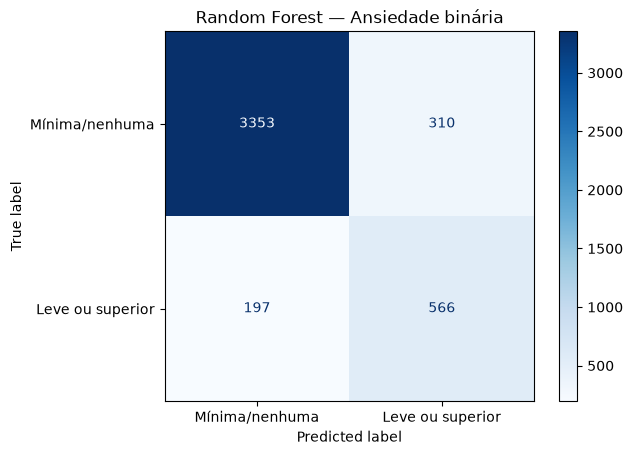

In [7]:
y_pred = modelo_final.predict(X_test)
y_proba = modelo_final.predict_proba(X_test)[:, 1]

print("Relatório de classificação (ponderado pelos pesos amostrais):")
print(classification_report(
    y_test, y_pred, sample_weight=w_test,
    target_names=["Mínima/nenhuma", "Leve ou superior"],
    zero_division=0
))

print("Acurácia:", round(accuracy_score(y_test, y_pred, sample_weight=w_test), 4))
print("Balanced accuracy:", round(balanced_accuracy_score(y_test, y_pred, sample_weight=w_test), 4))
print("F1 da classe positiva:", round(f1_score(y_test, y_pred, pos_label=1, sample_weight=w_test), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_proba, sample_weight=w_test), 4))

cm_amostral = confusion_matrix(y_test, y_pred, labels=[0, 1])
cm_ponderada = confusion_matrix(y_test, y_pred, labels=[0, 1], sample_weight=w_test)
print("Matriz de confusão — contagem de registros:")
print(cm_amostral)
print("Matriz de confusão — soma dos pesos amostrais (estimativa ponderada):")
print(np.round(cm_ponderada).astype(int))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=["Mínima/nenhuma", "Leve ou superior"],
    cmap="Blues", values_format="d"
)
plt.title("Random Forest — Ansiedade binária")
plt.show()


## 7. Importância das variáveis

,feature_transformada,importancia
140,cat__FREQ_SENTIU_DEPRIMIDO_2SEM_1,0.072766
156,cat__FREQ_AUTOAVALIACAO_NEGTIVA_2SEM_1,0.068453
136,cat__FREQ_PERDA_INTERESSE_2SEM_1,0.053720
160,cat__FREQ_DIFICULDADE_CONCENTRACAO_2SEM_1,0.046950
148,cat__FREQ_CANSASO_2SEM_1,0.044208
141,cat__FREQ_SENTIU_DEPRIMIDO_2SEM_2,0.041966
144,cat__FREQ_DIFICULDADE_DORMIR_2SEM_1,0.041819
157,cat__FREQ_AUTOAVALIACAO_NEGTIVA_2SEM_2,0.027804
152,cat__FREQ_HIPOREXIA_COMPULSAO_ALIMENTAR_2SEM_1,0.027637
168,cat__FREQ_SOLITARIO_1,0.025886


,variavel_original_aprox,importancia
22,FREQ_SENTIU_DEPRIMIDO_2SEM,0.126714
16,FREQ_AUTOAVALIACAO_NEGTIVA_2SEM,0.106650
21,FREQ_PERDA_INTERESSE_2SEM,0.080667
17,FREQ_CANSASO_2SEM,0.076159
18,FREQ_DIFICULDADE_CONCENTRACAO_2SEM,0.075298
19,FREQ_DIFICULDADE_DORMIR_2SEM,0.065298
23,FREQ_SOLITARIO,0.045015
20,FREQ_HIPOREXIA_COMPULSAO_ALIMENTAR_2SEM,0.043388
48,TIPO_DIFICULDADE_COGNITIVA,0.031873
31,MODIFICACAO_VELOCIDADE_FALA,0.022545


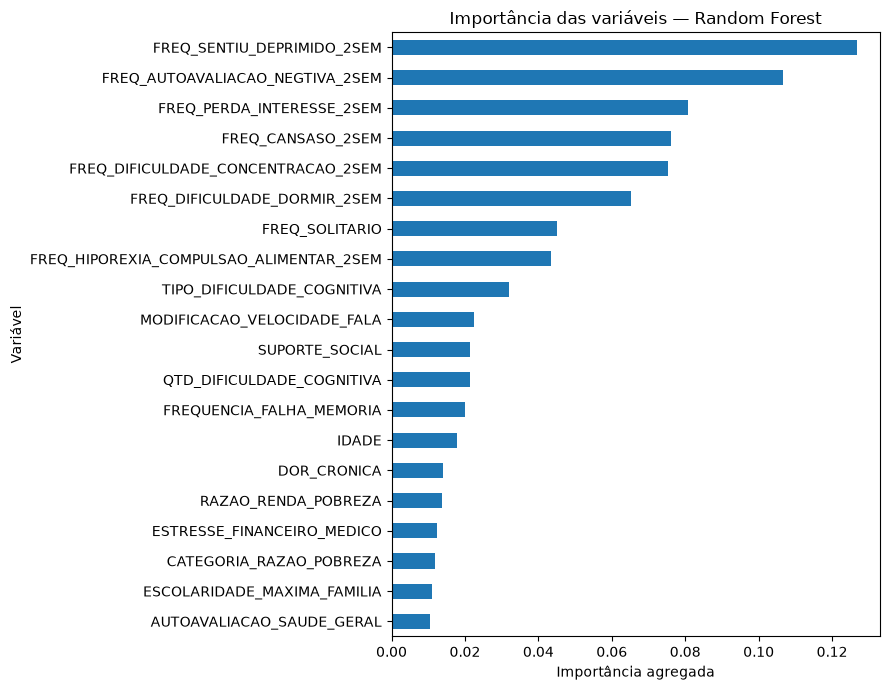

In [8]:
# Importância por variável original: soma das importâncias das categorias One-Hot
# pertencentes à mesma variável, para facilitar a interpretação.
prep = modelo_final.named_steps["preprocessor"]
rf = modelo_final.named_steps["model"]

feature_names = prep.get_feature_names_out()
importancias = pd.DataFrame({
    "feature_transformada": feature_names,
    "importancia": rf.feature_importances_
}).sort_values("importancia", ascending=False)

display(importancias.head(25))

# Importância agregada por coluna original
def nome_variavel_original(nome):
    if nome.startswith("num__"):
        return nome.replace("num__", "", 1)
    if nome.startswith("cat__"):
        resto = nome.replace("cat__", "", 1)
        # Encontra o nome original completo, inclusive quando contém underscores.
        candidatas = [c for c in cat_cols if resto.startswith(c + "_")]
        if candidatas:
            return max(candidatas, key=len)
        return resto
    return nome

importancias["variavel_original_aprox"] = importancias["feature_transformada"].map(nome_variavel_original)
importancia_agregada = (
    importancias.groupby("variavel_original_aprox", as_index=False)["importancia"]
    .sum().sort_values("importancia", ascending=False)
)
display(importancia_agregada.head(20))

importancia_agregada.head(20).sort_values("importancia").plot(
    x="variavel_original_aprox", y="importancia", kind="barh",
    figsize=(9, 7), legend=False
)
plt.xlabel("Importância agregada")
plt.ylabel("Variável")
plt.title("Importância das variáveis — Random Forest")
plt.tight_layout()
plt.show()
